# GPR processing — Phase 2

**PulseEKKO → dewow → time zero → bandpass → background removal → gain → optional topography / migration → export**.

Every stage follows **preview → compare → accept**. Running the acceptance cell is an explicit decision. Original raw data remains in `gpr`. All methods are in companion Python files; no notebook-specific processing code.

## Setup and read PulseEKKO files
Keep `.hd` and `.dt1` alongside the notebook, or change `base` to a path. If packages are missing run `%pip install -r requirements.txt` once. Plotly is optional.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from io_gpr import read_pulseekko
from plotting import plot_section, compare_sections, plot_depth_section, plot_radargram_interactive
from processing import dewow, timezero, bandpass, background_remove, gain, migration
from geometry import read_geometry_csv, elevation_grid
from export_gpr import export_section

base="line1"
gpr=read_pulseekko(base)
gpr_current=gpr
history=[]
print(gpr.name, gpr.amplitudes.shape, f"dt={gpr.dt_ns:.3f} ns",
      "Nyquist (MHz) =",500/gpr.dt_ns)

line1 (625, 202) dt=0.400 ns Nyquist (MHz) = 1250.0


## 0. Raw section (baseline)
The 99th-percentile red–white–blue colour clipping is **display-only**.

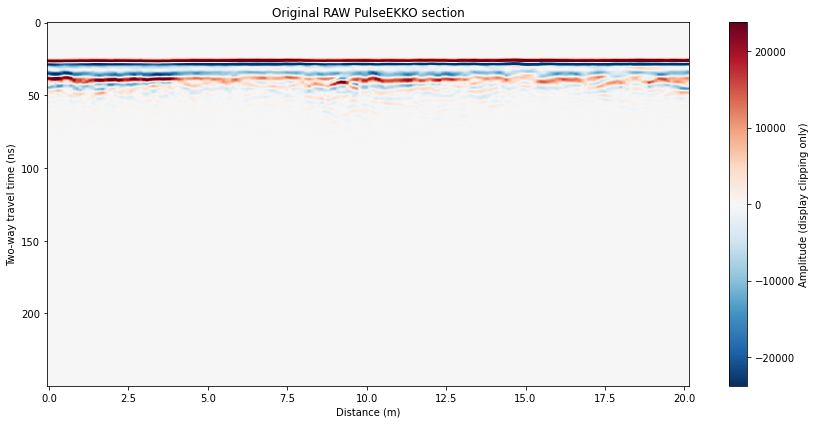

In [2]:
fig, ax=plot_section(gpr, title="Original RAW PulseEKKO section")
plt.show()

### Optional browser-interactive zoom (Plotly)
If Plotly is not installed, skip this cell. The Matplotlib workflow works independently.

plot_radargram_interactive(gpr, title="Raw PulseEKKO (interactive)").show()

## 1. Dewow
10 ns is a reasonable first trial for 200 MHz data, but compare 10, 15, and 20 ns.

In [3]:
window_ns=10.0
preview=dewow(gpr_current, window_ns=window_ns)
fig,_=compare_sections(gpr_current,preview,f"Dewow: {window_ns:g} ns")
plt.close(fig)
handle = display(fig, display_id=True)

None

In [4]:
# ACCEPT stage 1 (skip this cell to reject)
gpr_current=preview
history.append({"name":"dewow","window_ns":window_ns})
print("Accepted:",history[-1])
handle.update(None)

Accepted: {'name': 'dewow', 'window_ns': 10.0}


## 2. Time-zero correction
**The PulseEKKO header records sample 63.5**. This is a useful initial reference, not necessarily the physically optimal time-zero. Compare with the direct-wave onset before accepting. The method shifts the time axis **without resampling or discarding data**.

In [5]:
header_timezero_sample=float(gpr.header.get("TIMEZERO AT POINT",0))
shift_ns=header_timezero_sample*gpr.dt_ns  # verify visually against direct-wave onset
preview=timezero(gpr_current,shift_ns=shift_ns)
print("Proposed time shift:",shift_ns,"ns")
fig,_=compare_sections(gpr_current,preview,"Time-zero: axis shift only")
plt.close(fig)
handle = display(fig, display_id=True)

Proposed time shift: 25.400000000000002 ns


None

In [6]:
# ACCEPT stage 2 (skip to reject)
gpr_current=preview
history.append({"name":"timezero","shift_ns":shift_ns,"source":"header sample position"})
handle.update(None)

## 3. Bandpass
Zero-phase Butterworth filter along time. The cutoffs (MHz) must be below the Nyquist frequency. Compare reflected wavelets and direct wave; a more restrictive bandpass is not always better.

In [7]:
low_mhz,high_mhz,order=50.0,400.0,4
preview=bandpass(gpr_current,low_mhz=low_mhz,high_mhz=high_mhz,order=order)
fig,_=compare_sections(gpr_current,preview,f"Bandpass {low_mhz:g}–{high_mhz:g} MHz")
plt.close(fig)
handle = display(fig, display_id=True)

None

In [8]:
# ACCEPT stage 3 (skip to reject)
gpr_current=preview
history.append({"name":"bandpass","low_mhz":low_mhz,"high_mhz":high_mhz,"order":order})
handle.update(None)

## 4. Background removal (optional)
Subtract a fraction of the mean trace (at each time sample). **Warning:** this can erase real laterally continuous reflectors. Inspect carefully; it should not be used by default on every line.

In [9]:
strength=0.3  # 0=no removal; 1=full mean trace subtraction
preview=background_remove(gpr_current,strength=strength)
fig,_=compare_sections(gpr_current,preview,f"Background removal: strength={strength:g}")
plt.close(fig)
handle = display(fig, display_id=True)

None

In [10]:
# OPTIONAL ACCEPT stage 4: skip this cell to preserve continuous reflections
gpr_current=preview
history.append({"name":"background_remove","strength":strength})
handle.update(None)

## 5. Gain (optional)
Choose ONE gain initially. AGC alters relative amplitudes; power and exponential apply deterministic time-dependent gain. Preview cautiously; visually strong results are not necessarily quantitatively better.

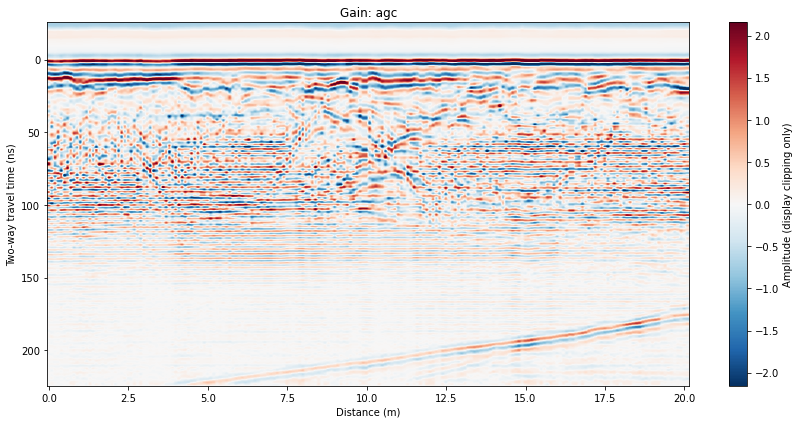

In [11]:
gain_method = "agc" # "power", "exponential", or "agc"
gain_parameters={"power":{"exponent":3.0,"reference_ns":10.0},
                 "exponential":{"rate_per_ns":0.008},
                 "agc":{"window_ns":30.0,"floor_fraction":.002}}
preview = gain( gpr_current, method=gain_method, **gain_parameters[gain_method])

fig, ax = plot_section(preview, title=f"Gain: {gain_method}")
plt.show()

In [12]:
# OPTIONAL ACCEPT stage 5
gpr_current=preview
history.append({"name":"gain","method":gain_method,**gain_parameters[gain_method]})

## 6. Inspect accepted section and export
The accepted processing sequence is recorded in `history`. Be mindful that re-running an acceptance cell duplicates the history entry; if in doubt, rerun the notebook from the start.

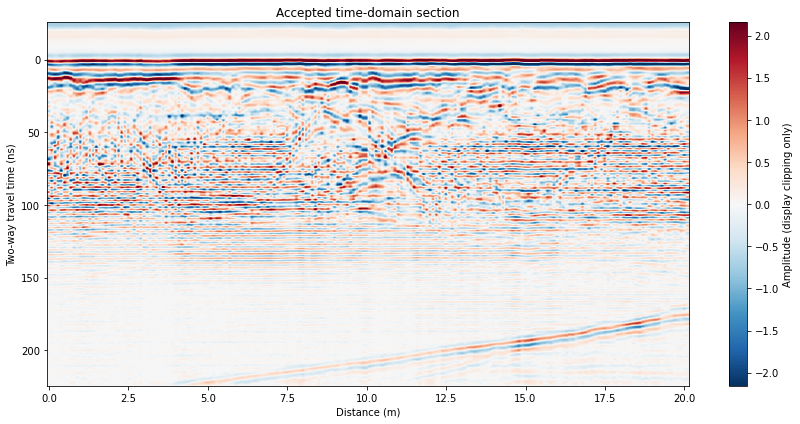

Saved: ('line1_processed.npz', 'line1_processed.json')


In [13]:
fig,ax=plot_section(gpr_current,"Accepted time-domain section")
plt.show()
fig.savefig(base+"_processed.png",dpi=220)
fig.savefig(base+"_processed.pdf")
files=export_section(gpr_current,base+"_processed",history)
print("Saved:",files)

## 7. Optional positioning and topography
Supply a `geometry.csv` containing ordered 1-based `trace,x,y,elevation` columns (or `trace,distance_m,elevation`). Nothing is applied to signal amplitudes. `elevation_grid` is a **display remapping** using constant velocity, not migration. When there is no CSV, skip this cell.

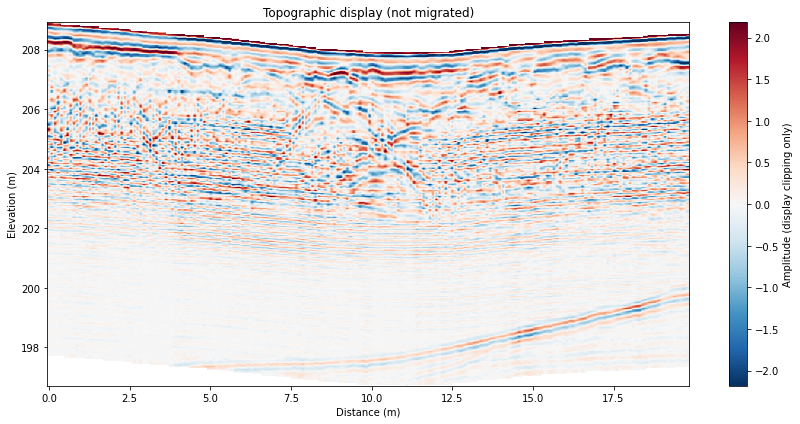

In [14]:
from pathlib import Path
import numpy as np
from geometry import read_geometry_csv, read_geometry_txt, elevation_grid

#geometry_file = None
geometry_file = "line1topo.txt"

velocity_m_ns = 0.10

# 1. Set geometry
if geometry_file is None:
    geometry = {
        "distance_m": gpr_current.distance_m.copy(),
        "elevation_m": np.zeros(gpr_current.amplitudes.shape[1])
    }
else:
    if Path(geometry_file).suffix.lower() == ".txt":
        geometry = read_geometry_txt(geometry_file, gpr_current)
    else:
        geometry = read_geometry_csv(geometry_file, gpr_current)

# 2. Calculate elevation grid ALWAYS
elevations, grid = elevation_grid(
    gpr_current,
    geometry,
    velocity_m_ns=velocity_m_ns
)

# 3. Plot the result
fig, ax = plot_depth_section(
    geometry["distance_m"],
    elevations,
    grid,
    "Flat-surface display" if geometry_file is None
        else "Topographic display (not migrated)",
    elevation=True
)

plt.show()
fig.savefig(base + "_topographic.png", dpi=220)

## 8. Optional educational Kirchhoff migration
This **basic constant-velocity diffraction stack** assumes flat topography, equally spaced midpoint traces and a constant radar velocity. It accounts for a stated antenna separation using symmetric transmitter/receiver positions. It does not provide amplitude-preserving imaging, anti-aliasing or topography-aware ray paths. Do not interpret its output as a validated quantitative migration.

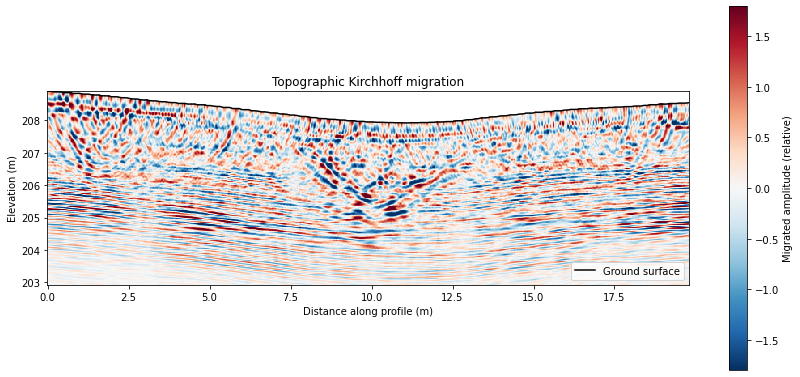

In [15]:
from migration_topo import (
    migrate_topography,
    plot_migrated_topography
)

# Migration parameters
velocity_m_ns = 0.07
aperture_m = 2.5
tx_rx_sep_m = 0.5

# Perform migration
x_mig, z_mig, migrated = migrate_topography(
    gpr_current,
    geometry,
    velocity_m_ns=velocity_m_ns,
    max_depth_m=5.0,
    dx_m=0.025,
    dz_m=0.025,
    aperture_m=aperture_m,
    tx_rx_sep_m=tx_rx_sep_m
)

# Display migrated section
fig, ax = plot_migrated_topography(
    x_mig,
    z_mig,
    migrated,
    ground_distance_m=geometry["distance_m"],
    ground_elevation_m=geometry["elevation_m"],
    title="Topographic Kirchhoff migration"
)
# Maintain a consistent physical aspect ratio. 
vertical_exaggeration = 1.0  # 1.0 is no exaggeration

ax.set_aspect(
    vertical_exaggeration,
    adjustable="box"
)

plt.show()

plt.close(fig)

### Notes for students
- **Do not automatically accept all steps.** Use the previews, and skip any processing that damages useful signal.
- If you change an earlier accepted stage, rerun the notebook from the first import cell in order.
- Saving an image does not embed coordinate reference systems: retain axes, geometry CSV and JSON provenance.
- The original `.dt1` and `.hd` files are never overwritten.